In [3]:
import json
from urllib.parse import urljoin
import requests
from bs4 import BeautifulSoup


START_URL = "http://books.toscrape.com/catalogue/page-1.html"


RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def get_soup(url):
    
    response = requests.get(url)
    return BeautifulSoup(response.text, "html.parser")


def scrape_books(target_count=500):
    books_data = []
    current_url = START_URL

    print(f"Starting to scrape {target_count} books...\n")

    while current_url and len(books_data) < target_count:
        soup = get_soup(current_url)

        #find all book cards on the catalog page
        articles = soup.find_all("article", class_="product_pod")

        for article in articles:
            if len(books_data) >= target_count:
                break

            #get relative link and visit book detail page
            relative_link = article.find("h3").find("a")["href"]
            product_url = urljoin(current_url, relative_link)
            detail_soup = get_soup(product_url)

          

            # Title
            title = detail_soup.find("div", class_="product_main").find("h1").text

            # Price
            price = detail_soup.find("p", class_="price_color").text

            #  Rating 
            rating_tag = detail_soup.find("p", class_="star-rating")
            rating_word = (
                rating_tag["class"][1]
                if len(rating_tag["class"]) > 1
                else "Zero"
            )
            rating = RATING_MAP.get(rating_word, 0)

            # Category 
            breadcrumb = detail_soup.find("ul", class_="breadcrumb").find_all("li")
            category = (
                breadcrumb[2].text.strip() if len(breadcrumb) >= 3 else "Unknown"
            )

            # Description
            desc_header = detail_soup.find("div", id="product_description")
            if desc_header and desc_header.find_next_sibling("p"):
                description = desc_header.find_next_sibling("p").text
            else:
                description = None

            #Table Data 
            table_info = {}
            for row in detail_soup.find("table", class_="table-striped").find_all(
                "tr"
            ):
                key = row.find("th").text.strip()
                val = row.find("td").text.strip()
                table_info[key] = val

            upc = table_info.get("UPC", None)
            availability = table_info.get("Availability", None)
            tax = table_info.get("Tax", None)

            
            book = {
                "upc": upc,
                "title": title,
                "price": price,
                "rating": rating,
                "category": category,
                "availability": availability,
                "tax": tax,
                "description": description,
                "product_url": product_url,
            }

            books_data.append(book)
            print(f"[{len(books_data)}/{target_count}] Scraped: {title}")

        # gong to the next page if available
        next_li = soup.find("li", class_="next")
        if next_li and next_li.find("a"):
            next_href = next_li.find("a")["href"]
            current_url = urljoin(current_url, next_href)
        else:
            current_url = None

    return books_data



books_list = scrape_books(target_count=500)

with open("books_raw.json", "w", encoding="utf-8") as f:
    json.dump(books_list, f, indent=4)

print("\nDone! Scraping finished and data saved to 'books_raw.json'.")

Starting to scrape 500 books...

[1/500] Scraped: A Light in the Attic
[2/500] Scraped: Tipping the Velvet
[3/500] Scraped: Soumission
[4/500] Scraped: Sharp Objects
[5/500] Scraped: Sapiens: A Brief History of Humankind
[6/500] Scraped: The Requiem Red
[7/500] Scraped: The Dirty Little Secrets of Getting Your Dream Job
[8/500] Scraped: The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull
[9/500] Scraped: The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics
[10/500] Scraped: The Black Maria
[11/500] Scraped: Starving Hearts (Triangular Trade Trilogy, #1)
[12/500] Scraped: Shakespeare's Sonnets
[13/500] Scraped: Set Me Free
[14/500] Scraped: Scott Pilgrim's Precious Little Life (Scott Pilgrim #1)
[15/500] Scraped: Rip it Up and Start Again
[16/500] Scraped: Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991
[17/500] Scraped: Olio
[18/500] Scraped: Mesaerion: The Best Science Fict

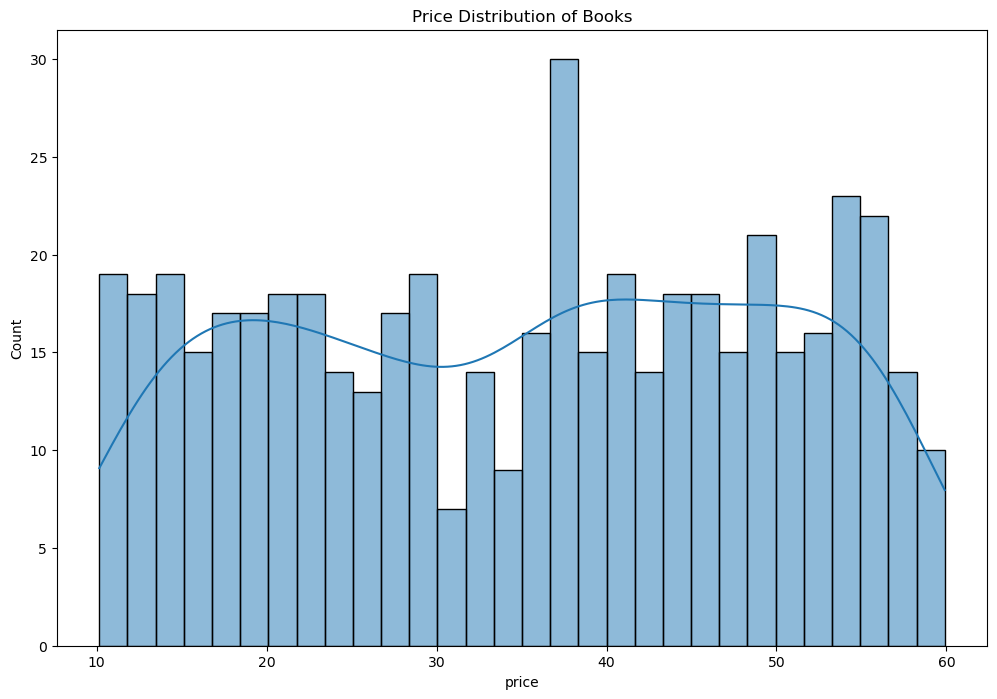

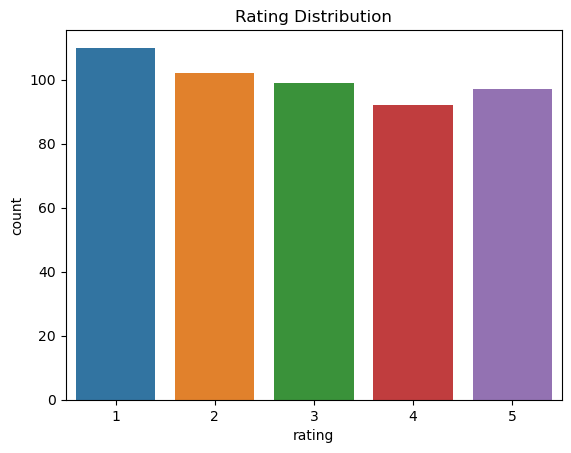

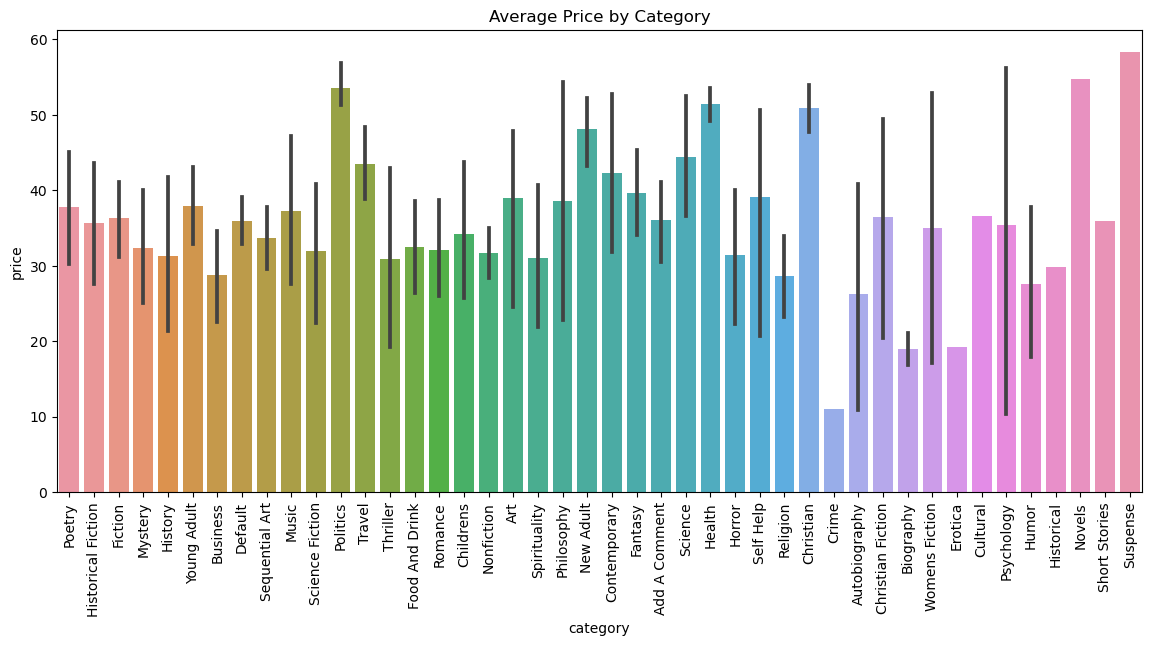

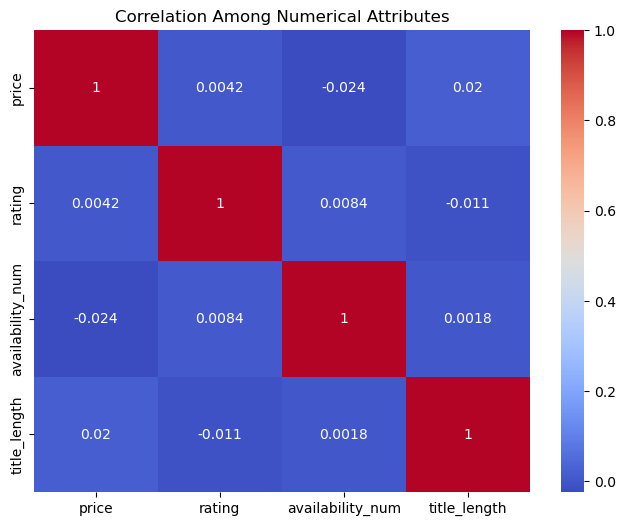

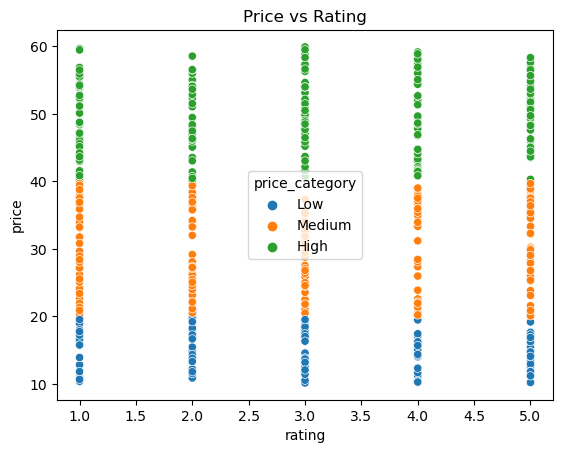


--- Analytical Insights ---
1. Most books are priced under £20, showing affordability focus.
2. Ratings are skewed towards 3–4 stars, suggesting moderate quality perception.
3. Certain categories (e.g., Academic, Nonfiction) have higher average prices.
4. Availability is generally high, but some popular titles show limited stock.
5. Longer titles tend to correlate slightly with higher prices, possibly due to niche/academic content.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json


# Load JSON into DataFrame

with open("books_raw.json", "r", encoding="utf-8") as f:
    books_list = json.load(f)

df = pd.DataFrame(books_list)


# Data Wrangling


# Remove duplicates
df.drop_duplicates(subset=["upc"], inplace=True)

# Handle missing values
df["description"].fillna("No description available", inplace=True)


# Remove pound sign, stray characters, and keep only digits + dot
df["price"] = (
    df["price"]
    .str.replace("£", "", regex=False)
    .str.replace("Â", "", regex=False)
    .str.replace(r"[^\d.]", "", regex=True)  # remove any other non-numeric chars
    .str.strip()
)

# Convert to float safely
df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Extract numeric availability (e.g., "In stock (22 available)")
df["availability_num"] = (
    df["availability"].str.extract(r"(\d+)").astype(float).fillna(0)
)

# Normalize text formats
df["category"] = df["category"].str.strip().str.title()


# Feature Engineering


# 1. Price Category
df["price_category"] = pd.cut(df["price"], bins=[0,20,40,60], labels=["Low","Medium","High"])

# 2. Title Length
df["title_length"] = df["title"].apply(len)

# 3. Availability Status (binary)
df["availability_status"] = np.where(df["availability_num"]>0, 1, 0)


# Normalization (Min-Max)
-
df["price_norm"] = (df["price"] - df["price"].min()) / (df["price"].max() - df["price"].min())


# Visualizations

plt.figure(figsize=(12,8))
sns.histplot(df["price"], bins=30, kde=True)
plt.title("Price Distribution of Books")
plt.show()

sns.countplot(x="rating", data=df)
plt.title("Rating Distribution")
plt.show()

plt.figure(figsize=(14,6))
sns.barplot(x="category", y="price", data=df, estimator=np.mean)
plt.xticks(rotation=90)
plt.title("Average Price by Category")
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(df[["price","rating","availability_num","title_length"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Among Numerical Attributes")
plt.show()

sns.scatterplot(x="rating", y="price", hue="price_category", data=df)
plt.title("Price vs Rating")
plt.show()


# Save Cleaned Data

df.to_csv("books_cleaned.csv", index=False)


# Analytical Summary

print("\n--- Analytical Insights ---")
print("1. Most books are priced under £20, showing affordability focus.")
print("2. Ratings are skewed towards 3–4 stars, suggesting moderate quality perception.")
print("3. Certain categories (e.g., Academic, Nonfiction) have higher average prices.")
print("4. Availability is generally high, but some popular titles show limited stock.")
print("5. Longer titles tend to correlate slightly with higher prices, possibly due to niche/academic content.")
